Exploratory Data Analysis [EDA]

In [1]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

from src.data.data_loader import load_data

In [2]:
df = load_data(file_path='D:\\Heart-Disease-Prediction\\data\\raw\\heart_disease_uci.csv')

1. Univariate Analysis

Numerical columns

<Axes: xlabel='age', ylabel='Count'>

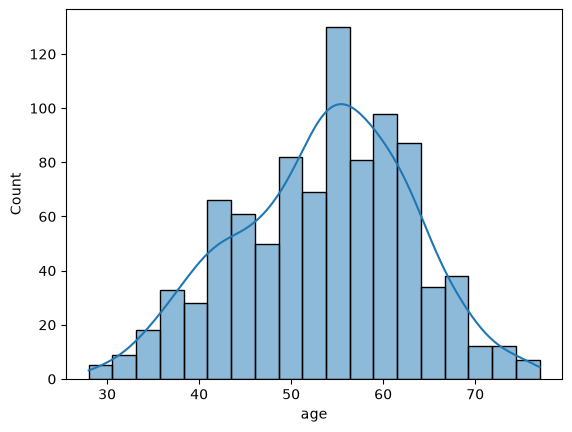

In [3]:
sns.histplot(data=df['age'], kde=True)

<Axes: xlabel='trestbps', ylabel='Count'>

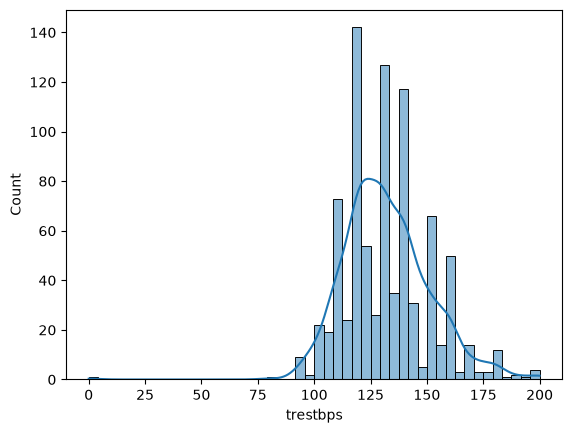

In [4]:
sns.histplot(data=df['trestbps'], kde=True)

<Axes: xlabel='chol', ylabel='Count'>

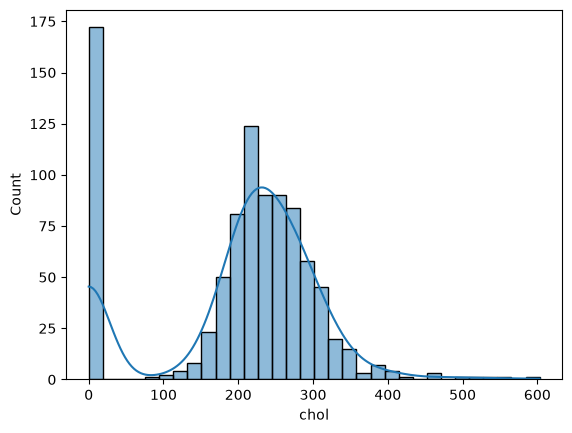

In [5]:
sns.histplot(data=df['chol'], kde=True)

<Axes: xlabel='oldpeak', ylabel='Count'>

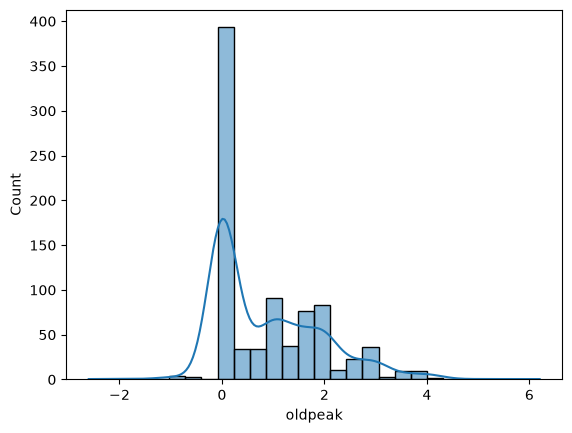

In [6]:
sns.histplot(data=df['oldpeak'],kde=True)

<Axes: xlabel='thalch', ylabel='Count'>

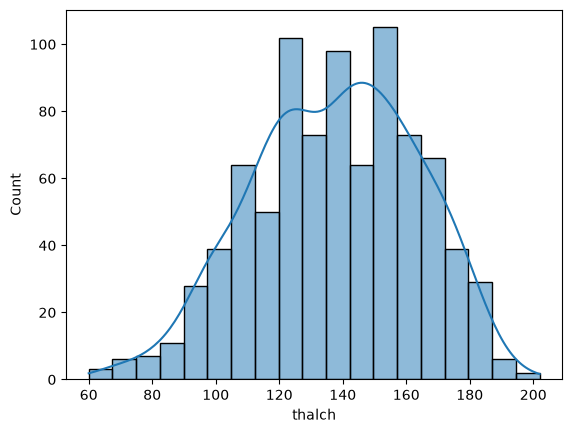

In [7]:
sns.histplot(data=df['thalch'],kde=True)

categorical columns

<Axes: xlabel='sex', ylabel='count'>

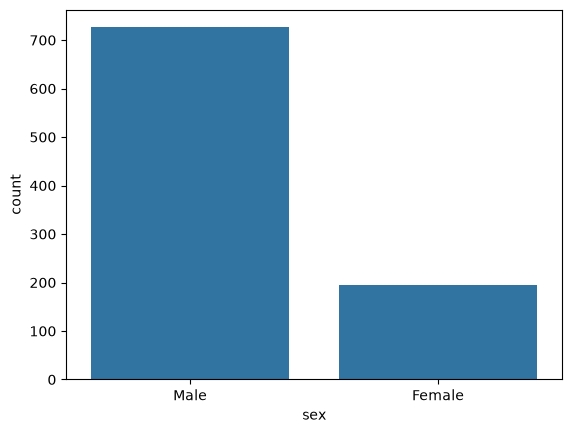

In [8]:
sns.countplot(data=df, x="sex")

<Axes: xlabel='dataset', ylabel='count'>

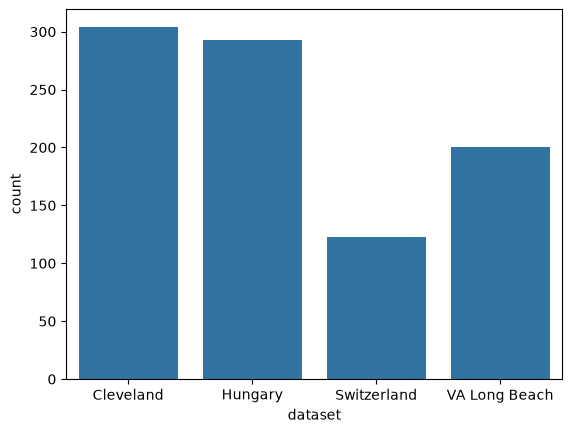

In [9]:
sns.countplot(data=df, x="dataset")

<Axes: xlabel='cp', ylabel='count'>

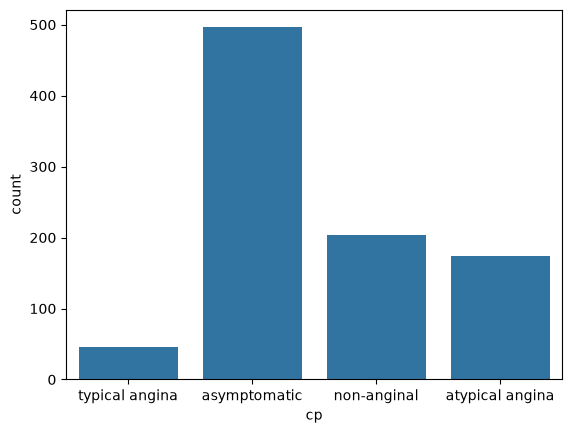

In [10]:
sns.countplot(data=df, x="cp")

<Axes: xlabel='fbs', ylabel='count'>

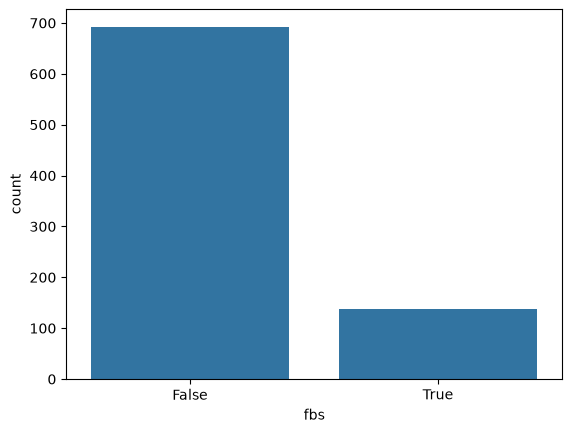

In [11]:
sns.countplot(data=df, x="fbs")

<Axes: xlabel='restecg', ylabel='count'>

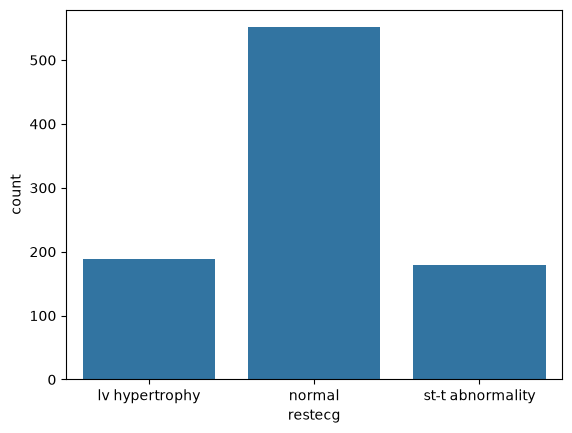

In [12]:
sns.countplot(data=df, x="restecg")

<Axes: xlabel='exang', ylabel='count'>

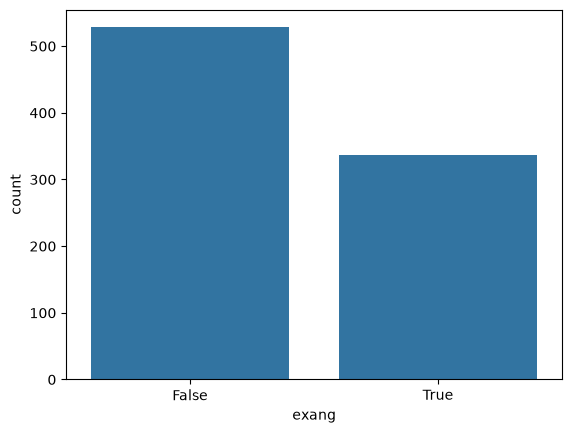

In [13]:
sns.countplot(data=df, x="exang")

<Axes: xlabel='slope', ylabel='count'>

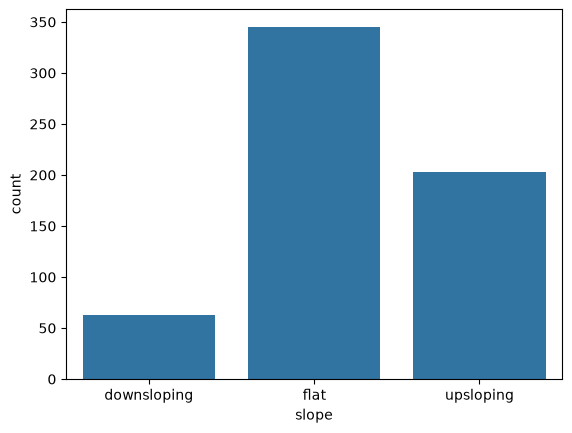

In [14]:
sns.countplot(data=df, x="slope")

<Axes: xlabel='thal', ylabel='count'>

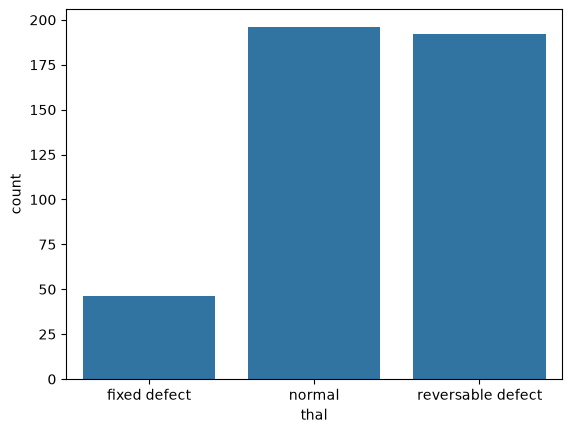

In [15]:
sns.countplot(data=df, x="thal")

Bivariate analysis

<Axes: xlabel='dataset', ylabel='ca'>

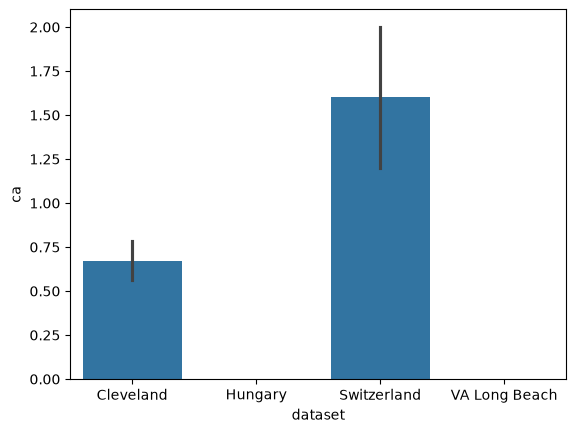

In [16]:
sns.barplot(x=df['dataset'], y=df['ca'])

<Axes: xlabel='dataset', ylabel='count'>

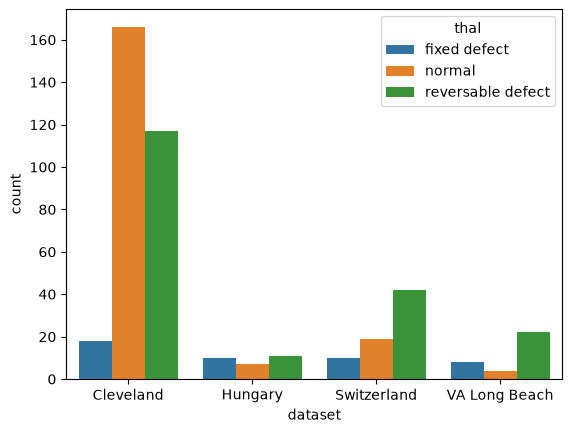

In [28]:
sns.countplot(x='dataset', hue='thal', data=df)

<Axes: xlabel='num', ylabel='ca'>

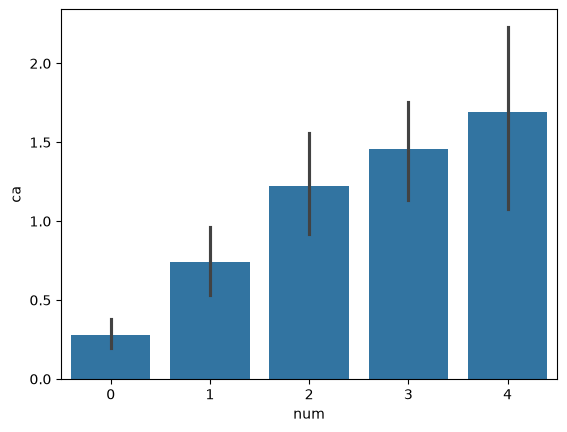

In [18]:
sns.barplot(x=df['num'], y=df['ca'])

<Axes: xlabel='thal', ylabel='count'>

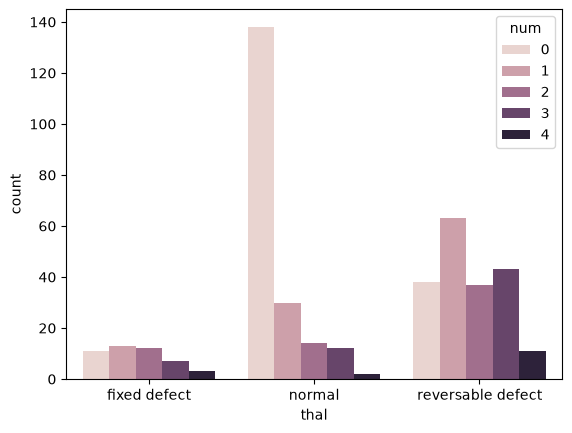

In [19]:
sns.countplot(x='thal', hue='num', data=df)

<Axes: xlabel='trestbps', ylabel='chol'>

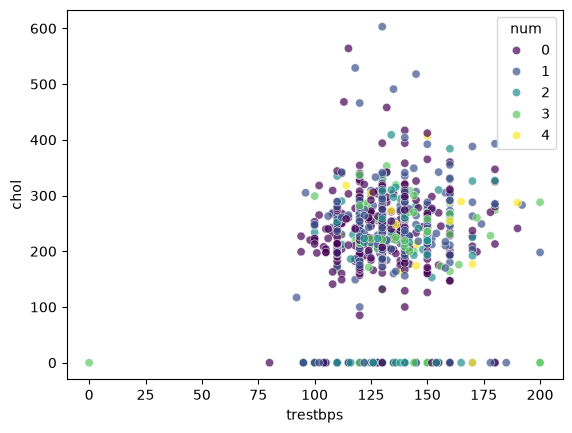

In [20]:
sns.scatterplot(
    data=df, 
    x='trestbps', 
    y='chol', 
    hue='num',     
    alpha=0.7,       
    palette='viridis'
)


<Axes: xlabel='trestbps', ylabel='thalch'>

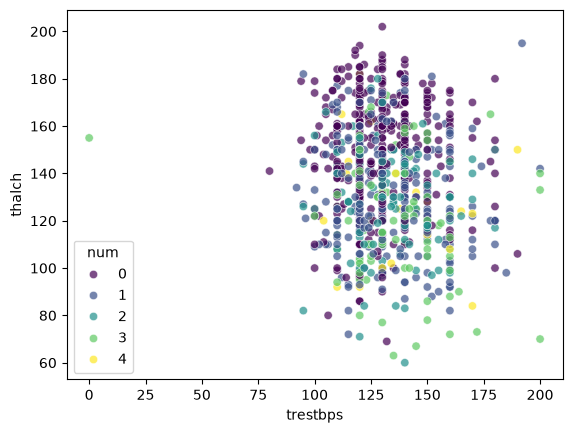

In [21]:
sns.scatterplot(
    data=df, 
    x='trestbps', 
    y='thalch', 
    hue='num',     
    alpha=0.7,       
    palette='viridis'
)


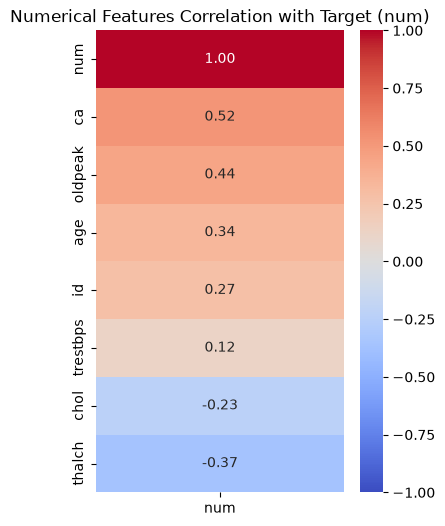

In [22]:
corr_matrix = df.select_dtypes(include=['number']).corr()

target_corr = corr_matrix[['num']].sort_values(by='num', ascending=False)

plt.figure(figsize=(4, 6))
sns.heatmap(target_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Numerical Features Correlation with Target (num)')
plt.show()

multivariate analysis

<Axes: >

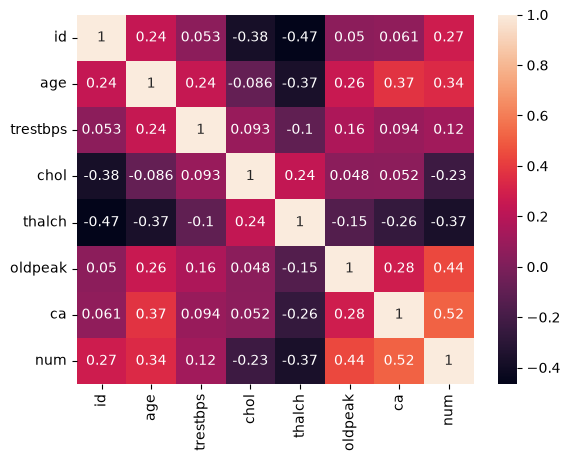

In [23]:
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True)

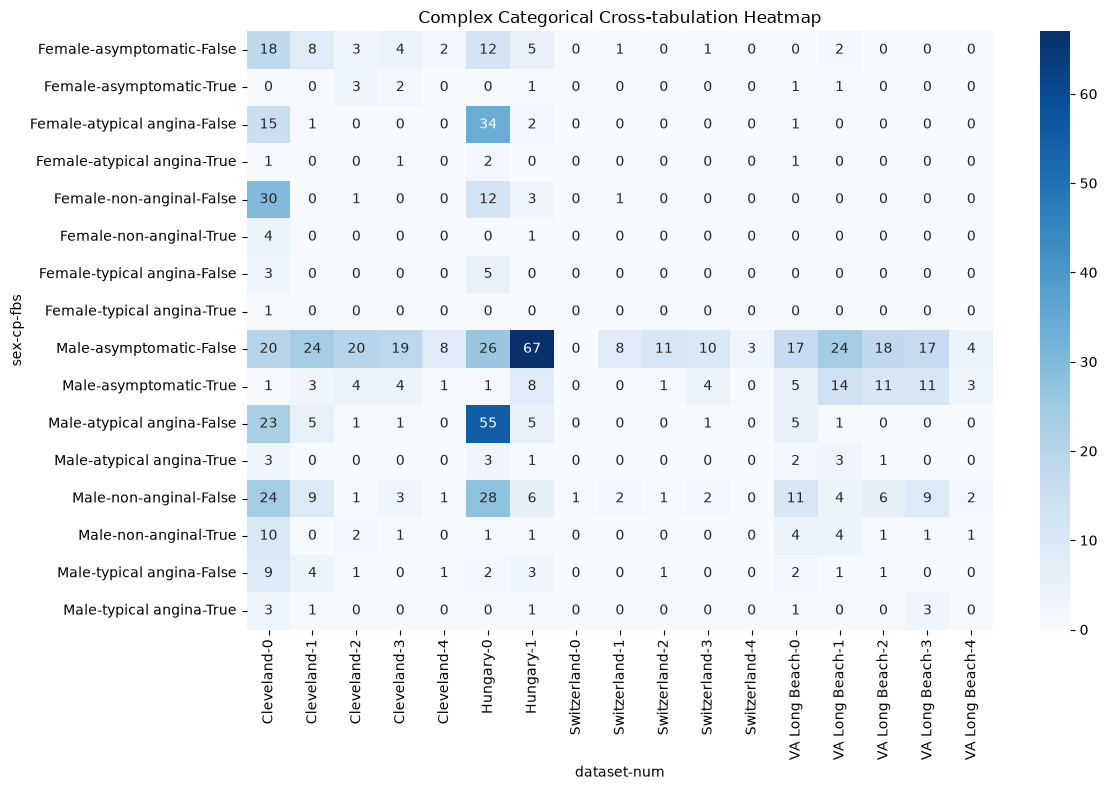

In [24]:
cross_tab = pd.crosstab(
    index=[df["sex"], df["cp"], df["fbs"]],  
    columns=[df["dataset"], df["num"]],
)

plt.figure(figsize=(12, 8))
sns.heatmap(cross_tab, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("Complex Categorical Cross-tabulation Heatmap")
plt.tight_layout()
plt.show()
